# 12 – Low-pass Cutoff Sensitivity

**Question.** The pipeline removes high-frequency sensor noise with a 40 Hz low-pass filter (Notebook 03). Was 40 Hz a good choice?

**Test.** Only the cutoff is changed; every other step stays as in the final pipeline. For each cutoff the left-dashboard signals are processed again, the features of the smartphone deployment configuration (**C7**: one dashboard sensor, orientation-invariant channels) are recomputed with the same windows and noise profiles, and the model is evaluated with **leave-one-vehicle-out (LOVO)** validation using XGBoost.

| Cutoff | Meaning |
|---|---|
| 20 Hz | keeps body and wheel motion only |
| 30 Hz | removes the upper part of the road texture band |
| **40 Hz** | **current pipeline** |
| 45 Hz | the highest cutoff allowed by the pipeline (0.9 × Nyquist) |
| none | no low-pass filter |

This notebook only reads the existing data on Drive and does not change any file, feature set or the deployment model.

In [ ]:
# Setup: mount Drive and import the shared Component 4 pipeline (MyDrive/PVS_Code/c4_pipeline.py)
import os, sys, time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import display
import warnings
warnings.filterwarnings('ignore')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

CODE_DIR = os.path.join(os.environ.get('C4_DRIVE', '/content/drive/MyDrive'), 'PVS_Code')
sys.path.insert(0, CODE_DIR)
import c4_pipeline as c4
importlib.reload(c4)
c4.check_setup()
print('Current low-pass cutoff:', c4.CFG['LOWPASS_HZ'], 'Hz')

Mounted at /content/drive
Drive folder      : /content/drive/MyDrive
Synced PVS1 found : True
Processed folder  : /content/drive/MyDrive/PVS_Processed True
Feature folder    : /content/drive/MyDrive/PVS_Feature_Datasets_v2 True
Results folder    : /content/drive/MyDrive/PVS_Model_Results_v2 True
Current low-pass cutoff: 40.0 Hz


## 1. Signal processing with a chosen cutoff
`process_left_dashboard` repeats the noise handling of `c4.process_sensor` for the deployed sensor (saturation replacement, gravity removal, low-pass filter, orientation-invariant channels). The only difference is that the low-pass cutoff is a parameter; `None` skips the low-pass filter.

In [ ]:
SENSOR = c4.CFG['DEPLOY_SENSOR']
NAMES = [f'{SENSOR}__{c}' for c in c4.PROC_CH]

def process_left_dashboard(seg, cutoff):
    A = seg[c4.sensor_cols(SENSOR, 'acc')].values.astype(float)
    G = seg[c4.sensor_cols(SENSOR, 'gyro')].values.astype(float)
    raw = np.hstack([A, G])
    lim = np.array([c4.CFG['ACC_FULL_SCALE']] * 3 + [c4.CFG['GYRO_FULL_SCALE']] * 3)
    sat = np.abs(raw) >= 0.98 * lim                                  # full-scale glitches only
    x = raw.copy()
    if sat.any():
        x[sat] = signal.medfilt(raw, kernel_size=[5, 1])[sat]
    A2, G2 = x[:, :3], x[:, 3:]
    grav = signal.sosfiltfilt(c4._sos('low', c4.CFG['GRAVITY_HZ']), A2, axis=0)
    if cutoff is None:
        dyn, Gf = A2 - grav, G2
    else:
        lp = c4._sos('low', min(cutoff, 0.9 * c4.nyq()))
        dyn = signal.sosfiltfilt(lp, A2 - grav, axis=0)
        Gf = signal.sosfiltfilt(lp, G2, axis=0)
    gu = c4._unit(grav)
    vert = (dyn * gu).sum(1)
    horiz = np.linalg.norm(dyn - vert[:, None] * gu, axis=1)
    return np.column_stack([dyn, Gf, vert, horiz, np.linalg.norm(dyn, axis=1), np.linalg.norm(Gf, axis=1)])

## 2. Load the cleaned trips once
The trips are cleaned exactly as in Notebook 03 (same units, same segments), so the window start indices of `windows.parquet` and the stationary windows stored by Notebook 03 still apply.

In [ ]:
data0 = c4.load_data()
A = data0.A
UNITS = c4.detect_units(c4.load_trip(1))
trips, stat = {}, {}
t0 = time.time()
for n in range(1, 10):
    df, _ = c4.clean_trip(c4.harmonise_units(c4.load_trip(n), UNITS))
    trips[n] = df
    stat[n] = c4.load_trip_signals(n)['STAT']
    print(f'PVS{n}: {len(df):,} rows, {len(stat[n])} stationary windows ({time.time() - t0:.0f}s)')

PVS1: 144,036 rows, 60 stationary windows (6s)
PVS2: 124,684 rows, 25 stationary windows (19s)
PVS3: 105,816 rows, 46 stationary windows (27s)
PVS4: 132,492 rows, 27 stationary windows (36s)
PVS5: 133,877 rows, 26 stationary windows (47s)
PVS6: 96,279 rows, 23 stationary windows (54s)
PVS7: 128,548 rows, 33 stationary windows (64s)
PVS8: 123,618 rows, 31 stationary windows (72s)
PVS9: 91,555 rows, 19 stationary windows (78s)


## 3. Features for one cutoff
For every trip: process the signals, estimate the vehicle noise profile from the stationary windows, and compute the same time and PSD features as Notebook 04. Only the left-dashboard columns are replaced; C7 uses no other sensor.

In [ ]:
def features_for(cutoff):
    parts = []
    for n in range(1, 10):
        df = trips[n]
        PROC = np.zeros((len(df), len(NAMES)), np.float32)
        for _, idx in df.groupby('segment_id', sort=False).indices.items():
            PROC[idx] = process_left_dashboard(df.iloc[idx], cutoff)
        noise = c4.noise_profile(PROC, stat[n])
        starts = A.loc[A.pvs == n, 'start'].values
        parts.append(c4.compute_features(PROC, NAMES, starts, noise=noise))
    F_new = pd.concat(parts, ignore_index=True)
    F = data0.F_PROC.copy()
    F[F_new.columns] = F_new.values
    return F

# Check: the 40 Hz rebuild must reproduce the features of Notebook 04
F40 = features_for(40.0)
cols = [c for c in F40.columns if f'{SENSOR}__' in c]
diff = np.nanmax(np.abs(F40[cols].values.astype(float) - data0.F_PROC[cols].values.astype(float)))
print(f'Max difference to the stored 40 Hz features: {diff:.2e}')
assert diff < 1e-3, 'The rebuild does not reproduce Notebook 04 - stop and check'

Max difference to the stored 40 Hz features: 0.00e+00


## 4. LOVO evaluation for each cutoff

In [ ]:
C7 = 'C7 Deployment (phone)'
CFG7 = c4.ablation_configs()[C7]
CUTOFFS = [20.0, 30.0, 40.0, 45.0, None]
rows, feats = [], {40.0: F40}
for cut in CUTOFFS:
    t0 = time.time()
    F = feats.get(cut)
    if F is None:
        F = features_for(cut)
    data = c4.C4Data(A, data0.F_RAW, F)
    r, _ = c4.run(data, C7, CFG7, ['LOVO'], ('XGB',), verbose=False)
    label = 'none' if cut is None else f'{cut:g} Hz'
    for _, x in r.iterrows():
        rows.append({'cutoff': label, 'fold': x.fold, 'macro_f1': x.macro_f1, 'recall_bad': x.recall_bad})
    print(f'{label:>6}: LOVO macro-F1 {r.macro_f1.mean():.3f} ± {r.macro_f1.std():.3f} '
          f'| bad recall {r.recall_bad.mean():.3f} ({time.time() - t0:.0f}s)')
RES = pd.DataFrame(rows)

 20 Hz: LOVO macro-F1 0.808 ± 0.016 | bad recall 0.647 (22s)
 30 Hz: LOVO macro-F1 0.833 ± 0.009 | bad recall 0.697 (24s)
 40 Hz: LOVO macro-F1 0.828 ± 0.008 | bad recall 0.676 (17s)
 45 Hz: LOVO macro-F1 0.836 ± 0.006 | bad recall 0.687 (26s)
  none: LOVO macro-F1 0.846 ± 0.016 | bad recall 0.663 (21s)


## 5. Results

,macro_f1,std,recall_bad
cutoff,,,
20 Hz,0.808,0.016,0.647
30 Hz,0.833,0.009,0.697
40 Hz,0.828,0.008,0.676
45 Hz,0.836,0.006,0.687
none,0.846,0.016,0.663


fold,test=Fiat Bravo,test=Fiat Palio,test=VW Saveiro
cutoff,,,
20 Hz,0.790,0.820,0.814
30 Hz,0.827,0.828,0.843
40 Hz,0.819,0.833,0.831
45 Hz,0.838,0.841,0.829
none,0.828,0.852,0.857


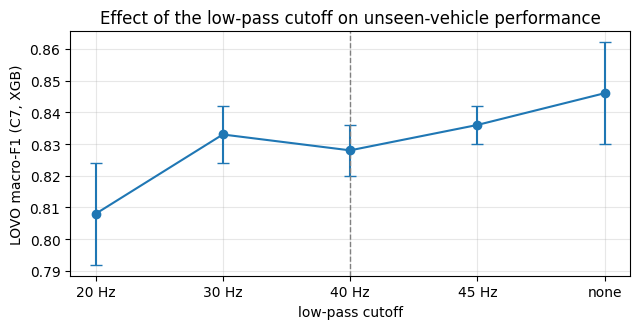

Best cutoff: none; 40 Hz is 0.018 below it (fold std of 40 Hz: 0.008).


In [ ]:
order = ['20 Hz', '30 Hz', '40 Hz', '45 Hz', 'none']
summary = RES.groupby('cutoff').agg(macro_f1=('macro_f1', 'mean'), std=('macro_f1', 'std'),
                                    recall_bad=('recall_bad', 'mean')).reindex(order).round(3)
per_fold = RES.pivot(index='cutoff', columns='fold', values='macro_f1').reindex(order).round(3)
display(summary)
display(per_fold)
RES.to_csv(os.path.join(c4.RESULTS_DIR, 'lowpass_cutoff_sensitivity.csv'), index=False)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.errorbar(order, summary.macro_f1, yerr=summary['std'], marker='o', capsize=4, color='tab:blue')
ax.axvline(order.index('40 Hz'), color='grey', ls='--', lw=1)
ax.set_ylabel('LOVO macro-F1 (C7, XGB)'); ax.set_xlabel('low-pass cutoff')
ax.set_title('Effect of the low-pass cutoff on unseen-vehicle performance'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(c4.RESULTS_DIR, 'lowpass_cutoff_sensitivity.png'), dpi=150); plt.show()

best = summary.macro_f1.idxmax()
gap = summary.macro_f1.max() - summary.loc['40 Hz', 'macro_f1']
print(f'Best cutoff: {best}; 40 Hz is {gap:.3f} below it (fold std of 40 Hz: {summary.loc["40 Hz", "std"]:.3f}).')

## 6. Reading the result
* A difference smaller than the fold standard deviation (about 0.015) is within the variation between vehicles and is not treated as a real improvement.
* If 40 Hz is the best cutoff or within that margin of it, the choice made in Notebook 03 is confirmed.
* If another cutoff is clearly better, it is a candidate for the final version; the deployment model is only changed after re-running Notebooks 03–07 and 10–11 and re-checking the app.